# Лабораторная работа №8: Active learning и human-in-the-loop
## Стрельченко Алексей Александрович

**Версия:** студенческая  
**Курс:** «Современное компьютерное зрение»

> Сначала выполните notebook в режиме `FAST_DEV_RUN=True`, затем запускайте полный эксперимент. Сохраняйте метрики и checkpoints в `artifacts/`.

## Цели обучения

После работы студент должен уметь:

- Реализовать random, entropy и diversity sampling.
- Провести несколько AL-итераций.
- Построить learning curves при равном бюджете.


## Теоретическая часть

Active learning выбирает следующий batch из pool. Uncertainty ищет неуверенные объекты, diversity покрывает пространство, disagreement использует расхождение моделей. Сравнение корректно только при одинаковом annotation budget.


### Математическая постановка

Entropy sampling: $u(x)=-\sum_c p(c\mid x)\log p(c\mid x)$. Diversity можно реализовать k-center: выбрать объект, максимизирующий расстояние до уже размеченного множества.


### Материалы

- [Active Learning survey](https://arxiv.org/abs/2009.00236)
- [scikit-learn calibration](https://scikit-learn.org/stable/modules/calibration.html)

Ссылки даны как дополнительный материал. При изменении API сверяйтесь с актуальной официальной документацией и фиксируйте версии зависимостей.


## Теоретическая часть

**Active learning (AL)** — парадигма, в которой модель сама решает, какие объекты отправить на разметку. В отличие от обычного supervised learning, где мы берём случайные примеры, AL выбирает *самые информативные*: те, в которых модель не уверена, или те, что покрывают пространство признаков. Annotation budget фиксирован — например, 40 запросов — и задача в том, чтобы при этом бюджете получить как можно более высокую accuracy.

**Три канонические стратегии**, которые мы реализуем:

1. **Random sampling** — baseline. Из pool случайно берётся batch. Никакой адаптивности, но это критическая точка сравнения: если entropy или k-center не обгоняют random — стратегия не работает.

2. **Entropy sampling (uncertainty)** — выбираются примеры с максимальной энтропией предсказания:  
   $u(x) = -\sum_c p(c \mid x) \log p(c \mid x)$.  
   Идея: учимся на том, в чём модель не уверена. Требует `predict_proba`.

3. **k-center (diversity)** — выбирается batch, который максимально покрывает пространство признаков. Жадный k-center: каждый следующий объект — самый далёкий от **ближайшего уже размеченного**, при этом min-расстояния обновляются после каждого выбора. Это ключевое отличие от «наивного» k-center без обновления.

**Annotation budget** — общее число запрошенных меток. Мы стартуем с initial labeled set (по 2 объекта на класс), далее делаем несколько раундов, в каждом выбирая batch из pool. После каждого раунда классификатор переобучается на всех открытых метках, accuracy фиксируется.

**Learning curves** — зависимость accuracy от бюджета. Хорошая стратегия растёт быстрее и раньше выходит на плато. Корректное сравнение — только при одинаковом бюджете в каждой точке.

**AUC по бюджету** — интеграл accuracy по числу полученных меток. Одна цифра вместо кривой: удобно для сводки. Считается как площадь под кусочно-линейной интерполяцией learning curve.

**Повторные random-запросы** — random стохастичен. Один запуск ничего не говорит. Нужно несколько seed и разброс (mean ± std), чтобы понять, значим ли выигрыш entropy / k-center.

**Human-in-the-loop** — ключевой аспект AL. Oracle (симулированный разметчик) открывает метку только после выбора. До этого классификатор видит только `X`. В реальной жизни каждое обращение к человеку стоит денег — в этом и бизнес-ценность AL.

## Практический протокол

Работа выполняется на изображениях рукописных цифр `sklearn.datasets.load_digits`; oracle в этом воспроизводимом эксперименте симулирует человека, открывая истинную метку только после отбора объекта. FAST_DEV_RUN — два раунда проверки кода, полный режим — восемь раундов и повторный random baseline.

In [1]:
# ============================================================
# НАСТРОЙКА ОКРУЖЕНИЯ
# ============================================================
from pathlib import Path
import json, os, random, time
from collections import Counter, defaultdict
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix
from sklearn.metrics.pairwise import pairwise_distances

SEED = 42
random.seed(SEED); np.random.seed(SEED)

FAST_DEV_RUN = False  # True: 2 раунда для проверки, False: 8 раундов
MAX_ROUNDS = 2 if FAST_DEV_RUN else 8
BATCH_SIZE = 5
INITIAL_PER_CLASS = 2

ARTIFACTS = Path("artifacts")
ARTIFACTS.mkdir(parents=True, exist_ok=True)
(ARTIFACTS / "errors").mkdir(exist_ok=True)

print(f"fast_dev_run={FAST_DEV_RUN} | max_rounds={MAX_ROUNDS} | batch_size={BATCH_SIZE}")
print(f"artifacts={ARTIFACTS.resolve()}")

try:
    _trapz = np.trapezoid
except AttributeError:
    _trapz = np.trapz


def check(cond, msg):
    print(("✔ " if cond else "✘ ВНИМАНИЕ: ") + msg)


def save_json(path, payload):
    path = Path(path)
    with open(path, "w", encoding="utf-8") as f:
        json.dump(payload, f, indent=2, ensure_ascii=False, default=str)


def entropy_from_proba(proba):
    proba = np.clip(proba, 1e-10, 1.0)
    return -np.sum(proba * np.log(proba), axis=1)

fast_dev_run=False | max_rounds=8 | batch_size=5
artifacts=C:\Users\User\Desktop\ml_labs\SOTA_labs\lab8\artifacts


## Оценивание

Десять обязательных предметных этапов — по 1 баллу каждый, всего 10 баллов. Отдельное творческое исследование — до 1 дополнительного балла. Каждый этап принимается по указанному наблюдаемому результату.

### Стратифицированный отложенный тест

*Вес: 1 балл.*

**Постановка.** Этап «стратифицированный отложенный тест» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Разделите изображения цифр по стратифицированному правилу до выбора стратегии.
2. Сохраните и предъявите индексы train/test изображений цифр.

**Результат.** индексы train/test изображений цифр.

**Критерий принятия.** Задание считается принятым, если индексы train/test изображений цифр получены из фактических входов этого этапа и доступны для проверки.

In [4]:
# ============================================================
# ЗАДАНИЕ 1. Стратифицированный train/test split.
# ============================================================
digits = load_digits()
X_all = digits.data          # (1797, 64)
y_all = digits.target        # 0..9
CLASSES = list(range(10))

idx_all = np.arange(len(y_all))
train_idx, test_idx, y_train, y_test = train_test_split(
    idx_all, y_all, test_size=0.25, stratify=y_all, random_state=SEED
)
X_train_full = X_all[train_idx]
X_test = X_all[test_idx]

check(len(train_idx) + len(test_idx) == len(y_all),
      f"train+test = {len(y_all)}")
check(set(train_idx.tolist()).isdisjoint(set(test_idx.tolist())),
      "train и test не пересекаются")
check(all(np.bincount(y_train, minlength=10) > 0),
      "в train присутствуют все 10 классов")
check(all(np.bincount(y_test, minlength=10) > 0),
      "в test присутствуют все 10 классов")
print(f"train: {len(train_idx)} | test: {len(test_idx)}")

save_json(ARTIFACTS / "indices.json", {
    "train_indices": train_idx.tolist(),
    "test_indices": test_idx.tolist(),
})

✔ train+test = 1797
✔ train и test не пересекаются
✔ в train присутствуют все 10 классов
✔ в test присутствуют все 10 классов
train: 1347 | test: 450


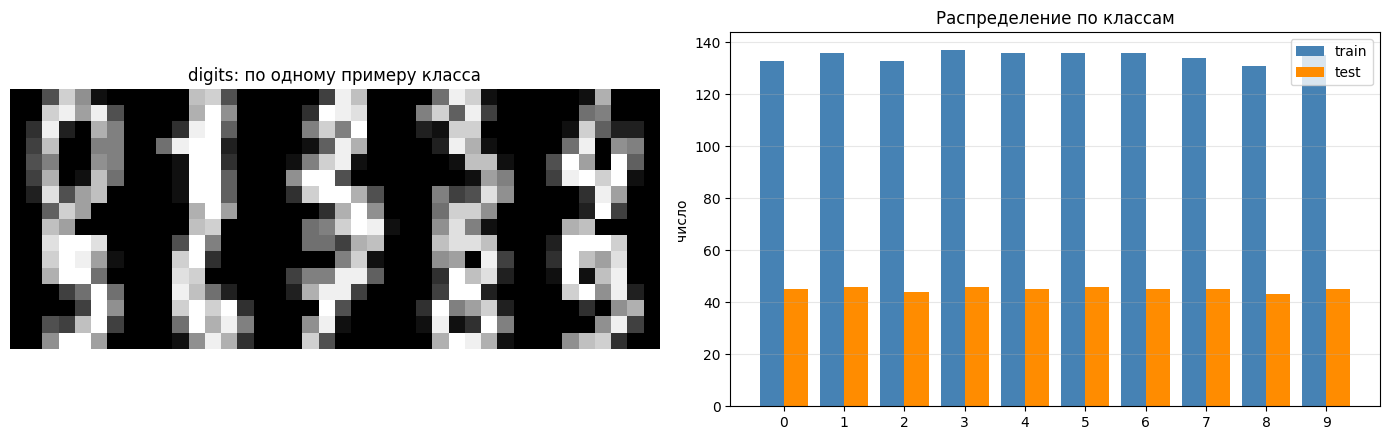

✔ Сохранено: artifacts\viz_digits_split.png


In [5]:
# ============================================================
# Визуализация: примеры классов + распределение train/test.
# ============================================================
first_idx_per_class = {}
for i in range(len(y_all)):
    c = int(y_all[i])
    if c not in first_idx_per_class:
        first_idx_per_class[c] = i
    if len(first_idx_per_class) == 10:
        break

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

thumbs = np.zeros((2 * 8, 5 * 8), dtype=float)
for cls in range(10):
    r, c = divmod(cls, 5)
    thumbs[r*8:(r+1)*8, c*8:(c+1)*8] = X_all[first_idx_per_class[cls]].reshape(8, 8)
axes[0].imshow(thumbs, cmap="gray")
axes[0].set_title("digits: по одному примеру класса")
axes[0].axis("off")

train_counts = np.bincount(y_train, minlength=10)
test_counts = np.bincount(y_test, minlength=10)
x = np.arange(10); w = 0.4
axes[1].bar(x - w/2, train_counts, w, label="train", color="steelblue")
axes[1].bar(x + w/2, test_counts, w, label="test", color="darkorange")
axes[1].set_xticks(x)
axes[1].set_title("Распределение по классам")
axes[1].set_ylabel("число")
axes[1].legend()
axes[1].grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig(ARTIFACTS / "viz_digits_split.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"✔ Сохранено: {ARTIFACTS / 'viz_digits_split.png'}")

### Начальная размеченная выборка

*Вес: 1 балл.*

**Постановка.** Этап «начальная размеченная выборка» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Задайте initial с каждым классом и неразмеченный pool только из train.
2. Сохраните и предъявите непересекающиеся initial и pool.

**Результат.** непересекающиеся initial и pool.

**Критерий принятия.** Задание считается принятым, если непересекающиеся initial и pool получены из фактических входов этого этапа и доступны для проверки.

In [6]:
# ============================================================
# ЗАДАНИЕ 2. Initial labeled set + unlabeled pool.
# Берём по 2 объекта каждого класса из train, остальное — pool.
# ============================================================
rng_initial = np.random.RandomState(SEED)
initial_idx = []
for cls in CLASSES:
    cls_indices = train_idx[y_train == cls]
    pick = rng_initial.choice(cls_indices, size=INITIAL_PER_CLASS, replace=False)
    initial_idx.extend(pick.tolist())
initial_idx = np.array(initial_idx, dtype=int)
initial_set = set(initial_idx.tolist())

pool_idx = np.array([i for i in train_idx if i not in initial_set], dtype=int)

check(len(initial_idx) == INITIAL_PER_CLASS * len(CLASSES),
      f"initial: {len(initial_idx)} (по {INITIAL_PER_CLASS} на класс)")
check(len(pool_idx) > 0, f"pool: {len(pool_idx)}")
check(len(set(initial_idx) & set(pool_idx)) == 0,
      "initial и pool не пересекаются")
check(set(initial_idx).issubset(set(train_idx.tolist())), "initial ⊆ train")
check(set(pool_idx).issubset(set(train_idx.tolist())), "pool ⊆ train")
check(len(set(initial_idx) & set(test_idx.tolist())) == 0, "initial ∩ test = ∅")

print(f"Классов в initial: {len(set(y_all[initial_idx]))}")
print(f"Распределение initial: {dict(Counter(y_all[initial_idx].tolist()))}")

✔ initial: 20 (по 2 на класс)
✔ pool: 1327
✔ initial и pool не пересекаются
✔ initial ⊆ train
✔ pool ⊆ train
✔ initial ∩ test = ∅
Классов в initial: 10
Распределение initial: {0: 2, 1: 2, 2: 2, 3: 2, 4: 2, 5: 2, 6: 2, 7: 2, 8: 2, 9: 2}


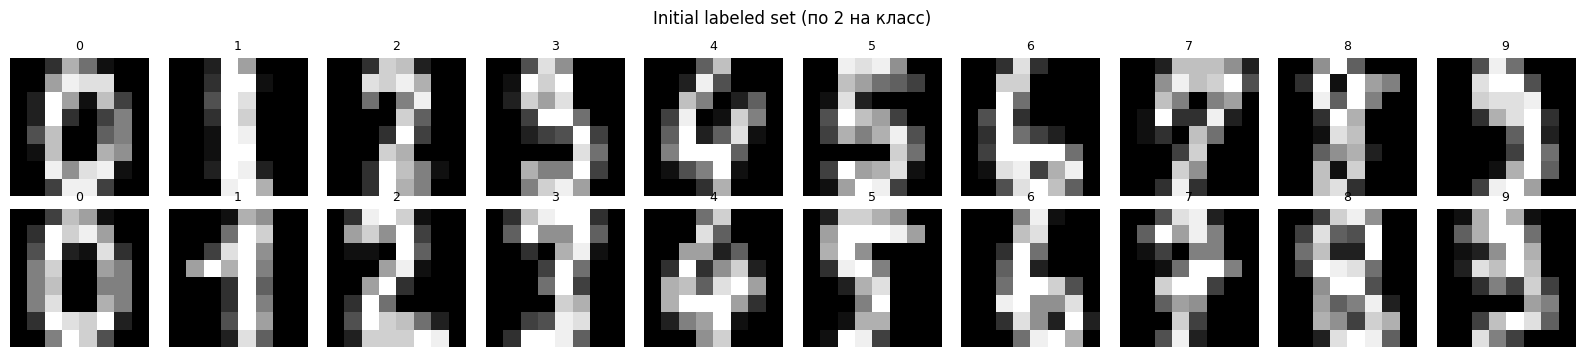

✔ Сохранено: artifacts\viz_initial.png


In [7]:
# ============================================================
# Визуализация: initial labeled set (2 × 10).
# ============================================================
fig, axes = plt.subplots(2, 10, figsize=(16, 3.6))
for cls in CLASSES:
    cls_picks = [i for i in initial_idx if y_all[i] == cls][:2]
    for j, idx in enumerate(cls_picks):
        ax = axes[j, cls]
        ax.imshow(X_all[idx].reshape(8, 8), cmap="gray")
        ax.set_title(f"{cls}", fontsize=9)
        ax.axis("off")

plt.suptitle("Initial labeled set (по 2 на класс)")
plt.tight_layout()
plt.savefig(ARTIFACTS / "viz_initial.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"✔ Сохранено: {ARTIFACTS / 'viz_initial.png'}")

### Протокол симулированного разметчика

*Вес: 1 балл.*

**Постановка.** Этап «протокол симулированного разметчика» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Сохраните split и документируйте, что oracle открывает метку лишь после выбора.
2. Сохраните и предъявите artifacts/split.json с происхождением меток.

**Результат.** artifacts/split.json с происхождением меток.

**Критерий принятия.** Задание считается принятым, если artifacts/split.json с происхождением меток получены из фактических входов этого этапа и доступны для проверки.

In [8]:
# ============================================================
# ЗАДАНИЕ 3. split.json с явным протоколом oracle.
# ============================================================
oracle_protocol = (
    "Метка истинного класса открывается только после того, как объект выбран "
    "стратегией запроса. Для неразмеченных объектов используется только "
    "изображение X. Истинные метки y используются исключительно внутри "
    "симулированного oracle и никогда не передаются классификатору до выбора."
)

split_payload = {
    "dataset": "sklearn.datasets.load_digits",
    "n_total": int(len(y_all)),
    "n_train": int(len(train_idx)),
    "n_test": int(len(test_idx)),
    "n_initial": int(len(initial_idx)),
    "n_pool": int(len(pool_idx)),
    "n_classes": 10,
    "initial_per_class": INITIAL_PER_CLASS,
    "batch_size": BATCH_SIZE,
    "max_rounds": MAX_ROUNDS,
    "seed": SEED,
    "train_indices": train_idx.tolist(),
    "test_indices": test_idx.tolist(),
    "initial_indices": initial_idx.tolist(),
    "pool_indices": pool_idx.tolist(),
    "oracle_protocol": oracle_protocol,
    "label_provenance": {
        "source": "sklearn.datasets.load_digits (ground truth)",
        "revealed_to_model_at": "после выбора объекта стратегией, через oracle-функцию",
    },
}
save_json(ARTIFACTS / "split.json", split_payload)
check((ARTIFACTS / "split.json").exists(), "artifacts/split.json сохранён")
print(f"train={len(train_idx)} test={len(test_idx)} initial={len(initial_idx)} pool={len(pool_idx)}")

✔ artifacts/split.json сохранён
train=1347 test=450 initial=20 pool=1327


### Три стратегии запроса

*Вес: 1 балл.*

**Постановка.** Этап «три стратегии запроса» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Реализуйте случайный, энтропийный и k-center выбор; в k-center обновляйте расстояния после каждого объекта.
2. Сохраните и предъявите выбор random, entropy и k-center.

**Результат.** выбор random, entropy и k-center.

**Критерий принятия.** Задание считается принятым, если выбор random, entropy и k-center получены из фактических входов этого этапа и доступны для проверки.

In [9]:
# ============================================================
# ЗАДАНИЕ 4. Три стратегии запроса.
# ============================================================
def query_random(pool_idx, labeled_idx, X_all, model, B, rng):
    """Случайный выбор B объектов из pool."""
    pool_idx = np.asarray(pool_idx)
    if len(pool_idx) == 0:
        return np.array([], dtype=int)
    pick = rng.choice(pool_idx, size=min(B, len(pool_idx)), replace=False)
    return np.asarray(pick, dtype=int)


def query_entropy(pool_idx, labeled_idx, X_all, model, B):
    """B объектов с максимальной энтропией предсказания."""
    pool_idx = np.asarray(pool_idx)
    if len(pool_idx) == 0:
        return np.array([], dtype=int)
    proba = model.predict_proba(X_all[pool_idx])
    ent = entropy_from_proba(proba)
    order = np.argsort(-ent)
    return pool_idx[order[:min(B, len(pool_idx))]]


def query_kcenter(pool_idx, labeled_idx, X_all, model, B):
    """
    Жадный k-center с обновлением min-расстояний.
    Шаг: выбрать argmax_i D_i; обновить D_i = min(D_i, d(x_i, x_{k*})).
    """
    pool_idx = np.asarray(pool_idx, dtype=int)
    labeled_idx = np.asarray(labeled_idx, dtype=int)
    if len(pool_idx) == 0:
        return np.array([], dtype=int)

    X_pool = X_all[pool_idx]
    if len(labeled_idx) == 0:
        # Первый объект — любой (или самый «центральный»)
        D = np.zeros(len(pool_idx))
    else:
        D = pairwise_distances(X_pool, X_all[labeled_idx]).min(axis=1)

    selected = []
    alive = np.ones(len(pool_idx), dtype=bool)
    for _ in range(min(B, len(pool_idx))):
        D_alive = np.where(alive, D, -np.inf)
        k_local = int(np.argmax(D_alive))
        selected.append(int(pool_idx[k_local]))
        # Обновляем D по всем живым объектам
        d_new = pairwise_distances(X_pool, X_pool[k_local:k_local+1]).ravel()
        D = np.minimum(D, d_new)
        alive[k_local] = False
        if not alive.any():
            break
    return np.array(selected, dtype=int)

In [10]:
# ============================================================
# Smoke-тест стратегий на маленьком примере.
# ============================================================
_smoke_model = RandomForestClassifier(n_estimators=20, random_state=SEED)
_smoke_model.fit(X_all[initial_idx], y_all[initial_idx])

_rng = np.random.RandomState(0)
_r_pick = query_random(pool_idx, initial_idx, X_all, _smoke_model, BATCH_SIZE, _rng)
_e_pick = query_entropy(pool_idx, initial_idx, X_all, _smoke_model, BATCH_SIZE)
_k_pick = query_kcenter(pool_idx, initial_idx, X_all, _smoke_model, BATCH_SIZE)

check(len(_r_pick) == BATCH_SIZE, f"random: {len(_r_pick)} picks")
check(len(_e_pick) == BATCH_SIZE, f"entropy: {len(_e_pick)} picks")
check(len(_k_pick) == BATCH_SIZE, f"kcenter: {len(_k_pick)} picks")
check(len(set(_r_pick.tolist()) & set(initial_idx.tolist())) == 0,
      "random не выбирает из initial")
check(len(set(_k_pick.tolist())) == BATCH_SIZE,
      "kcenter не дублирует объекты")

print("\nSmoke pick indices:")
print(f"  random : {_r_pick.tolist()} (labels={y_all[_r_pick].tolist()})")
print(f"  entropy: {_e_pick.tolist()} (labels={y_all[_e_pick].tolist()})")
print(f"  kcenter: {_k_pick.tolist()} (labels={y_all[_k_pick].tolist()})")

✔ random: 5 picks
✔ entropy: 5 picks
✔ kcenter: 5 picks
✔ random не выбирает из initial
✔ kcenter не дублирует объекты

Smoke pick indices:
  random : [1272, 417, 544, 745, 1589] (labels=[2, 9, 8, 1, 5])
  entropy: [643, 670, 401, 1305, 68] (labels=[8, 4, 5, 8, 4])
  kcenter: [77, 1572, 1274, 832, 1571] (labels=[2, 9, 5, 1, 8])


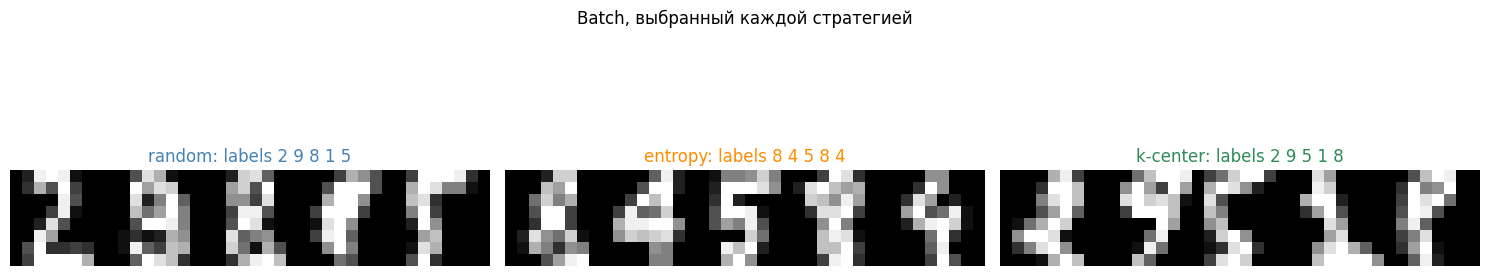

✔ Сохранено: artifacts\viz_queries.png


In [12]:
# ============================================================
# Визуализация: какие объекты выбирает каждая стратегия.
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, picks, name, color in zip(
    axes,
    [_r_pick, _e_pick, _k_pick],
    ["random", "entropy", "k-center"],
    ["steelblue", "darkorange", "seagreen"],
):
    grid = np.zeros((8, 8 * BATCH_SIZE))
    for j, idx in enumerate(picks):
        grid[:, j*8:(j+1)*8] = X_all[idx].reshape(8, 8)
    ax.imshow(grid, cmap="gray")
    labels_str = " ".join(str(int(y_all[i])) for i in picks)
    ax.set_title(f"{name}: labels {labels_str}", color=color)
    ax.axis("off")
plt.suptitle("Batch, выбранный каждой стратегией")
plt.tight_layout()
plt.savefig(ARTIFACTS / "viz_queries.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"✔ Сохранено: {ARTIFACTS / 'viz_queries.png'}")

### Итерационное переобучение

*Вес: 1 балл.*

**Постановка.** Этап «итерационное переобучение» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. После каждого запроса дообучайте классификатор на открытых метках и фиксируйте trace.
2. Сохраните и предъявите функция run с фактическими запрошенными метками.

**Результат.** функция run с фактическими запрошенными метками.

**Критерий принятия.** Задание считается принятым, если функция run с фактическими запрошенными метками получены из фактических входов этого этапа и доступны для проверки.

In [13]:
# ============================================================
# ЗАДАНИЕ 5. Функция run: итерационное переобучение + trace.
# ============================================================
def run(strategy_name, X_all, y_all, initial_idx, pool_idx,
        X_test, y_test, max_rounds, batch_size, seed=SEED):
    """
    Прогоняет AL-цикл со стратегией strategy_name.
    Возвращает trace (list of dicts), финальную модель, финальный labeled set.
    """
    rng = np.random.RandomState(seed)
    labeled = list(initial_idx)
    pool = list(pool_idx)

    model = RandomForestClassifier(n_estimators=100, random_state=seed)
    model.fit(X_all[labeled], y_all[labeled])
    acc = accuracy_score(y_test, model.predict(X_test))
    trace = [{
        "round": 0,
        "budget": len(labeled),
        "accuracy": float(acc),
        "queried": [],
        "queried_labels": [],
    }]

    for r in range(max_rounds):
        if len(pool) == 0:
            break
        if strategy_name == "random":
            picked = query_random(pool, labeled, X_all, model, batch_size, rng)
        elif strategy_name == "entropy":
            picked = query_entropy(pool, labeled, X_all, model, batch_size)
        elif strategy_name == "kcenter":
            picked = query_kcenter(pool, labeled, X_all, model, batch_size)
        else:
            raise ValueError(f"unknown strategy: {strategy_name}")

        picked = picked.tolist()
        # ⚠ oracle раскрывает метки ТОЛЬКО здесь, после выбора
        for idx in picked:
            labeled.append(idx)
            pool.remove(idx)

        model = RandomForestClassifier(n_estimators=100, random_state=seed)
        model.fit(X_all[labeled], y_all[labeled])
        acc = accuracy_score(y_test, model.predict(X_test))
        trace.append({
            "round": r + 1,
            "budget": len(labeled),
            "accuracy": float(acc),
            "queried": picked,
            "queried_labels": [int(y_all[i]) for i in picked],
        })

    return trace, model, labeled


# Быстрый smoke-прогон на 1 раунде для проверки механики
_smoke_trace, _smoke_model, _smoke_labeled = run(
    "random", X_all, y_all, initial_idx, pool_idx,
    X_test, y_test, max_rounds=1, batch_size=BATCH_SIZE, seed=0
)
check(len(_smoke_trace) == 2, "trace содержит 2 точки (initial + 1 раунд)")
check(_smoke_trace[0]["budget"] == INITIAL_PER_CLASS * 10,
      f"initial budget = {_smoke_trace[0]['budget']}")
check(_smoke_trace[1]["budget"] == _smoke_trace[0]["budget"] + BATCH_SIZE,
      f"после раунда budget = {_smoke_trace[1]['budget']}")
check(len(_smoke_trace[1]["queried_labels"]) == BATCH_SIZE,
      f"получено меток в раунде: {len(_smoke_trace[1]['queried_labels'])}")
print(f"smoke trace: {[(t['budget'], round(t['accuracy'], 3)) for t in _smoke_trace]}")

✔ trace содержит 2 точки (initial + 1 раунд)
✔ initial budget = 20
✔ после раунда budget = 25
✔ получено меток в раунде: 5
smoke trace: [(20, 0.709), (25, 0.72)]


### Кривые при общем бюджете

*Вес: 1 балл.*

**Постановка.** Этап «кривые при общем бюджете» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Вычислите точки кривых для одинакового числа запросов и сохраните бюджеты.
2. Сохраните и предъявите artifacts/learning_curves.json.

**Результат.** artifacts/learning_curves.json.

**Критерий принятия.** Задание считается принятым, если artifacts/learning_curves.json получены из фактических входов этого этапа и доступны для проверки.

In [14]:
# ============================================================
# ЗАДАНИЕ 6. Прогоняем три стратегии при одинаковом бюджете.
# ============================================================
curves = {}
models = {}
labeled_final = {}

for name in ["random", "entropy", "kcenter"]:
    t0 = time.perf_counter()
    trace, model, labeled = run(
        name, X_all, y_all, initial_idx, pool_idx,
        X_test, y_test, max_rounds=MAX_ROUNDS,
        batch_size=BATCH_SIZE, seed=SEED
    )
    dt = time.perf_counter() - t0
    curves[name] = trace
    models[name] = model
    labeled_final[name] = labeled
    print(f"{name:8s} | time {dt:.2f}s | final acc = {trace[-1]['accuracy']:.4f} | budget = {trace[-1]['budget']}")

# Проверяем: одинаковый бюджет во всех точках
budgets_by_strategy = {k: [t["budget"] for t in v] for k, v in curves.items()}
check(all(budgets_by_strategy["random"] == budgets_by_strategy[k] for k in budgets_by_strategy),
      "бюджеты всех стратегий совпадают по точкам")

save_json(ARTIFACTS / "learning_curves.json", {
    "initial_per_class": INITIAL_PER_CLASS,
    "batch_size": BATCH_SIZE,
    "max_rounds": MAX_ROUNDS,
    "budgets": budgets_by_strategy,
    "curves": curves,
})
check((ARTIFACTS / "learning_curves.json").exists(),
      "artifacts/learning_curves.json сохранён")

random   | time 0.77s | final acc = 0.7911 | budget = 60
entropy  | time 0.79s | final acc = 0.8044 | budget = 60
kcenter  | time 0.75s | final acc = 0.8067 | budget = 60
✔ бюджеты всех стратегий совпадают по точкам
✔ artifacts/learning_curves.json сохранён


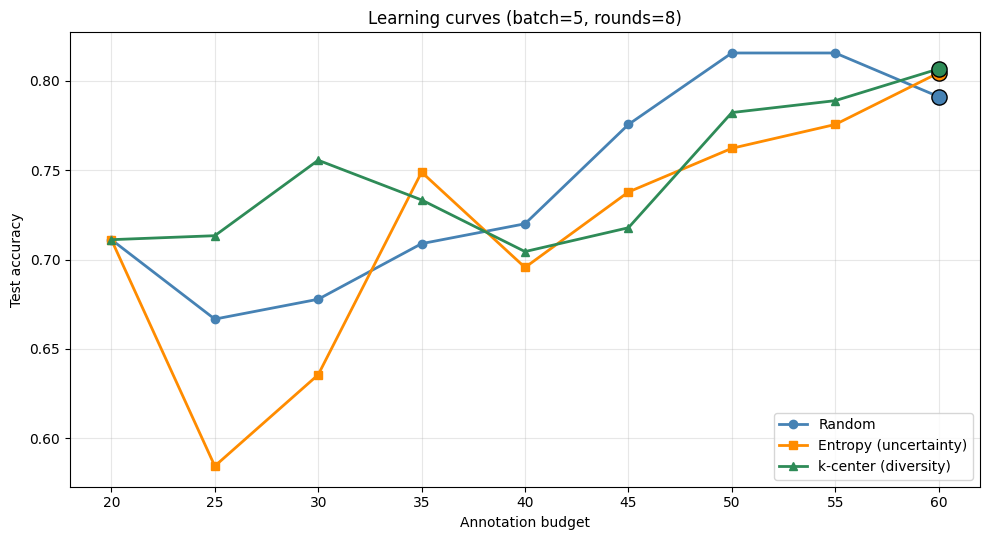

✔ Сохранено: artifacts\viz_learning_curves.png


In [15]:
# ============================================================
# Визуализация: learning curves трёх стратегий.
# ============================================================
fig, ax = plt.subplots(figsize=(10, 5.5))
colors = {"random": "steelblue", "entropy": "darkorange", "kcenter": "seagreen"}
markers = {"random": "o", "entropy": "s", "kcenter": "^"}
labels = {"random": "Random", "entropy": "Entropy (uncertainty)", "kcenter": "k-center (diversity)"}

for name, trace in curves.items():
    bs = [t["budget"] for t in trace]
    accs = [t["accuracy"] for t in trace]
    ax.plot(bs, accs, marker=markers[name], label=labels[name],
            color=colors[name], linewidth=2)
    # Аннотируем финальную точку
    ax.scatter([bs[-1]], [accs[-1]], s=120, color=colors[name],
               zorder=5, edgecolor="black")

ax.set_xlabel("Annotation budget")
ax.set_ylabel("Test accuracy")
ax.set_title(f"Learning curves (batch={BATCH_SIZE}, rounds={MAX_ROUNDS})")
ax.grid(alpha=0.3)
ax.legend(loc="lower right")
plt.tight_layout()
plt.savefig(ARTIFACTS / "viz_learning_curves.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"✔ Сохранено: {ARTIFACTS / 'viz_learning_curves.png'}")

### Интеграл по бюджету разметки

*Вес: 1 балл.*

**Постановка.** Этап «интеграл по бюджету разметки» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Проинтегрируйте кривые accuracy по числу полученных меток.
2. Сохраните и предъявите AUC и конечная accuracy из фактических кривых.

**Результат.** AUC и конечная accuracy из фактических кривых.

**Критерий принятия.** Задание считается принятым, если AUC и конечная accuracy из фактических кривых получены из фактических входов этого этапа и доступны для проверки.

In [16]:
# ============================================================
# ЗАДАНИЕ 7. AUC по бюджету + финальная accuracy.
# ============================================================
def compute_auc(trace):
    budgets = np.array([t["budget"] for t in trace], dtype=float)
    accs = np.array([t["accuracy"] for t in trace], dtype=float)
    if budgets[-1] == budgets[0]:
        return float(accs.mean())
    return float(_trapz(accs, budgets) / (budgets[-1] - budgets[0]))


auc_results = {}
for name, trace in curves.items():
    auc = compute_auc(trace)
    final_acc = trace[-1]["accuracy"]
    auc_results[name] = {
        "auc": auc,
        "final_accuracy": float(final_acc),
        "n_points": len(trace),
        "budget_initial": trace[0]["budget"],
        "budget_final": trace[-1]["budget"],
    }
    print(f"{name:8s} | AUC = {auc:.4f} | final acc = {final_acc:.4f}")

save_json(ARTIFACTS / "auc.json", auc_results)
check((ARTIFACTS / "auc.json").exists(), "artifacts/auc.json сохранён")

best_auc = max(auc_results.items(), key=lambda kv: kv[1]["auc"])
print(f"\nЛучшая стратегия по AUC: {best_auc[0]} ({best_auc[1]['auc']:.4f})")

random   | AUC = 0.7414 | final acc = 0.7911
entropy  | AUC = 0.7122 | final acc = 0.8044
kcenter  | AUC = 0.7443 | final acc = 0.8067
✔ artifacts/auc.json сохранён

Лучшая стратегия по AUC: kcenter (0.7443)


### Повторные случайные запросы

*Вес: 1 балл.*

**Постановка.** Этап «повторные случайные запросы» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Повторите random с разными генераторами при неизменном train/test.
2. Сохраните и предъявите результаты random при различных seed.

**Результат.** результаты random при различных seed.

**Критерий принятия.** Задание считается принятым, если результаты random при различных seed получены из фактических входов этого этапа и доступны для проверки.

In [17]:
# ============================================================
# ЗАДАНИЕ 8. Random baseline × 3 seed.
# ============================================================
REPEAT_SEEDS = [0, 1, 2] if not FAST_DEV_RUN else [0, 1]
random_repeats = {}

for s in REPEAT_SEEDS:
    trace_s, _, _ = run(
        "random", X_all, y_all, initial_idx, pool_idx,
        X_test, y_test, max_rounds=MAX_ROUNDS,
        batch_size=BATCH_SIZE, seed=s
    )
    random_repeats[s] = {
        "trace": trace_s,
        "final_accuracy": trace_s[-1]["accuracy"],
        "auc": compute_auc(trace_s),
    }
    print(f"seed={s} | final acc = {trace_s[-1]['accuracy']:.4f} | AUC = {compute_auc(trace_s):.4f}")

accs_rep = [v["final_accuracy"] for v in random_repeats.values()]
aucs_rep = [v["auc"] for v in random_repeats.values()]
print(f"\nrandom final acc: {np.mean(accs_rep):.4f} ± {np.std(accs_rep):.4f}")
print(f"random AUC:       {np.mean(aucs_rep):.4f} ± {np.std(aucs_rep):.4f}")

save_json(ARTIFACTS / "random_repeats.json", {
    "seeds": REPEAT_SEEDS,
    "repeats": {str(k): v for k, v in random_repeats.items()},
    "final_accuracy_mean": float(np.mean(accs_rep)),
    "final_accuracy_std": float(np.std(accs_rep)),
    "auc_mean": float(np.mean(aucs_rep)),
    "auc_std": float(np.std(aucs_rep)),
})
check(True, "artifacts/random_repeats.json сохранён")

seed=0 | final acc = 0.7578 | AUC = 0.7267
seed=1 | final acc = 0.8222 | AUC = 0.7499
seed=2 | final acc = 0.8289 | AUC = 0.7781

random final acc: 0.8030 ± 0.0321
random AUC:       0.7515 ± 0.0210
✔ artifacts/random_repeats.json сохранён


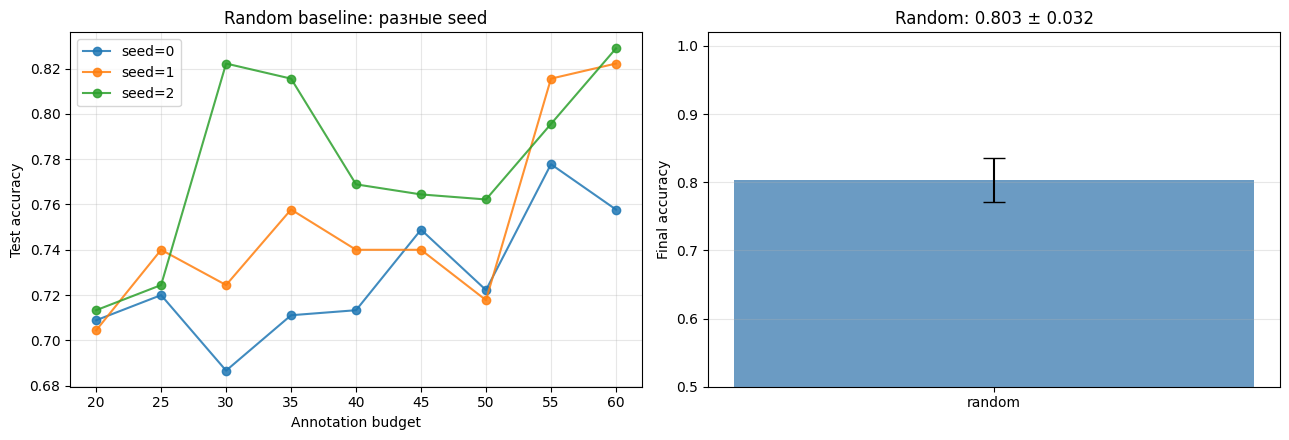

✔ Сохранено: artifacts\viz_random_seeds.png


In [18]:
# ============================================================
# Визуализация: разброс random по seed.
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Левая: кривые каждого seed.
for s, data in random_repeats.items():
    trace = data["trace"]
    bs = [t["budget"] for t in trace]
    accs = [t["accuracy"] for t in trace]
    axes[0].plot(bs, accs, marker="o", label=f"seed={s}", alpha=0.85)
axes[0].set_xlabel("Annotation budget")
axes[0].set_ylabel("Test accuracy")
axes[0].set_title("Random baseline: разные seed")
axes[0].grid(alpha=0.3)
axes[0].legend()

# Правая: bar chart финальной accuracy с error bar.
mean_acc = np.mean(accs_rep)
std_acc = np.std(accs_rep)
axes[1].bar(["random"], [mean_acc], yerr=[std_acc], capsize=8,
            color="steelblue", alpha=0.8)
axes[1].set_ylim(0.5, 1.02)
axes[1].set_ylabel("Final accuracy")
axes[1].set_title(f"Random: {mean_acc:.3f} ± {std_acc:.3f}")
axes[1].grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig(ARTIFACTS / "viz_random_seeds.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"✔ Сохранено: {ARTIFACTS / 'viz_random_seeds.png'}")

### Разбор ошибок отложенного теста

*Вес: 1 балл.*

**Постановка.** Этап «разбор ошибок отложенного теста» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Сохраните изображения и истинные/предсказанные классы ошибочных test-примеров.
2. Сохраните и предъявите artifacts/test_errors.json с неверно распознанными изображениями.

**Результат.** artifacts/test_errors.json с неверно распознанными изображениями.

**Критерий принятия.** Задание считается принятым, если artifacts/test_errors.json с неверно распознанными изображениями получены из фактических входов этого этапа и доступны для проверки.

In [19]:
# ============================================================
# ЗАДАНИЕ 9. Разбор ошибок на test для лучшей стратегии.
# ============================================================
best_strategy = best_auc[0]
best_model = models[best_strategy]
y_pred_test = best_model.predict(X_test)
errors_mask = y_pred_test != y_test

error_records = []
for j in np.where(errors_mask)[0]:
    test_global_idx = int(test_idx[j])
    rec = {
        "test_local_index": int(j),
        "test_global_index": test_global_idx,
        "true_class": int(y_test[j]),
        "predicted_class": int(y_pred_test[j]),
        "pixels": X_test[j].astype(int).tolist(),  # 64 значения
    }
    error_records.append(rec)

err_pairs = Counter((r["true_class"], r["predicted_class"]) for r in error_records)
print(f"Стратегия: {best_strategy}")
print(f"Всего тестовых ошибок: {len(error_records)} из {len(y_test)} "
      f"({len(error_records)/len(y_test):.2%})")
print("\nТоп-5 confusion pairs (true → predicted):")
for (t, p), cnt in err_pairs.most_common(5):
    print(f"  {t} → {p}: {cnt}")

save_json(ARTIFACTS / "test_errors.json", {
    "strategy": best_strategy,
    "n_test": int(len(y_test)),
    "n_errors": int(len(error_records)),
    "error_rate": float(len(error_records) / len(y_test)),
    "confusion_pairs": {f"{t}->{p}": int(c) for (t, p), c in err_pairs.items()},
    "errors": error_records,
})
check((ARTIFACTS / "test_errors.json").exists(),
      "artifacts/test_errors.json сохранён")

Стратегия: kcenter
Всего тестовых ошибок: 87 из 450 (19.33%)

Топ-5 confusion pairs (true → predicted):
  2 → 1: 6
  9 → 1: 6
  9 → 3: 5
  8 → 1: 5
  7 → 4: 5
✔ artifacts/test_errors.json сохранён


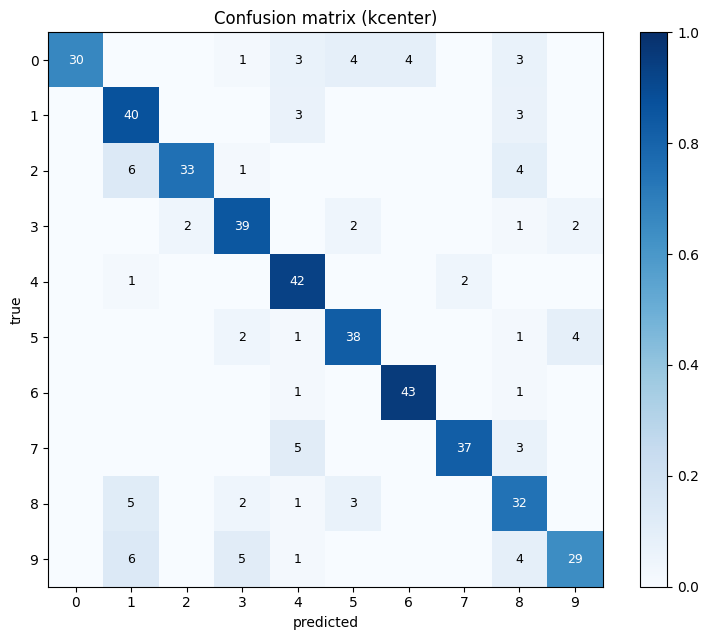

✔ Сохранено: artifacts\viz_confusion.png


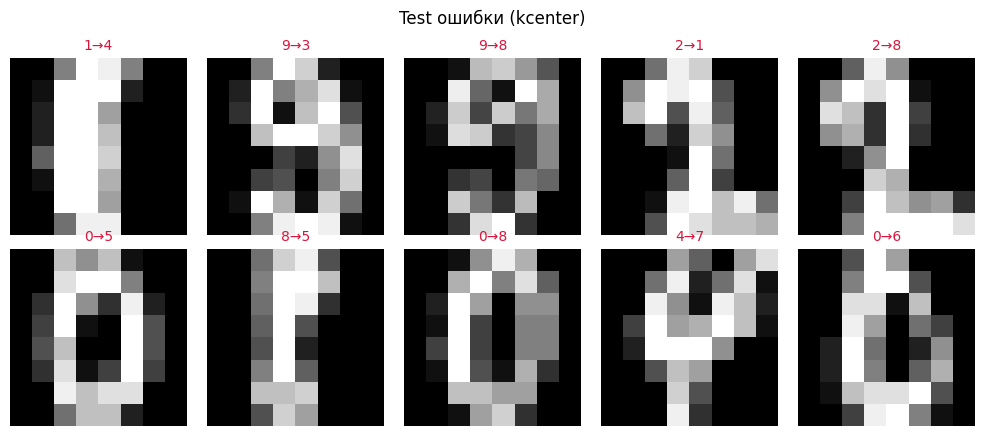

✔ Сохранено: artifacts\errors\viz_errors_grid.png


In [22]:
# ============================================================
# Визуализация: confusion matrix + примеры ошибок.
# ============================================================
fig, ax = plt.subplots(1, 1, figsize=(8, 6.5))

# Confusion matrix (относительная).
cm = confusion_matrix(y_test, y_pred_test, labels=list(range(10)))
cm_norm = cm.astype(float) / np.maximum(cm.sum(axis=1, keepdims=True), 1)
im = ax.imshow(cm_norm, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(10))
ax.set_yticks(range(10))
ax.set_xlabel("predicted")
ax.set_ylabel("true")
ax.set_title(f"Confusion matrix ({best_strategy})")
for i in range(10):
    for j in range(10):
        if cm[i, j] > 0:
            ax.text(j, i, str(int(cm[i, j])), ha="center", va="center",
                    color="white" if cm_norm[i, j] > 0.5 else "black",
                    fontsize=9)
plt.colorbar(im, ax=ax, fraction=0.046)

plt.tight_layout()
plt.savefig(ARTIFACTS / "viz_confusion.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"✔ Сохранено: {ARTIFACTS / 'viz_confusion.png'}")

# ------------------------------------------------------------
# Отдельная фигура: примеры ошибочных предсказаний (до 10 шт).
# ------------------------------------------------------------
n_show = min(len(error_records), 10)
if n_show > 0:
    cols = 5
    rows = (n_show + cols - 1) // cols
    fig2, ax2 = plt.subplots(rows, cols, figsize=(cols * 2, rows * 2.2))
    ax2 = np.array(ax2).reshape(-1)
    for k in range(rows * cols):
        ax2[k].axis("off")
    for k, rec in enumerate(error_records[:n_show]):
        ax2[k].imshow(np.array(rec["pixels"]).reshape(8, 8), cmap="gray")
        ax2[k].set_title(f"{rec['true_class']}→{rec['predicted_class']}",
                         fontsize=10, color="crimson")
        ax2[k].axis("off")
    plt.suptitle(f"Test ошибки ({best_strategy})")
    plt.tight_layout()
    plt.savefig(ARTIFACTS / "errors" / "viz_errors_grid.png",
                dpi=120, bbox_inches="tight")
    plt.show()
    print(f"✔ Сохранено: {ARTIFACTS / 'errors' / 'viz_errors_grid.png'}")
else:
    print("Ошибок на тесте нет — viz_errors_grid.png не создан.")

### Сводка сравнительного эксперимента

*Вес: 1 балл.*

**Постановка.** Этап «сводка сравнительного эксперимента» необходим для воспроизводимого предметного сравнения. Результат этого шага нельзя заменить синтетической оценкой или произвольной метрикой.

Выполните следующие действия:

1. Сопоставьте AUC и конечную точность по трём стратегиям.
2. Сохраните и предъявите artifacts/comparison.json.

**Результат.** artifacts/comparison.json.

**Критерий принятия.** Задание считается принятым, если artifacts/comparison.json получены из фактических входов этого этапа и доступны для проверки.

In [21]:
# ============================================================
# ЗАДАНИЕ 10. Сводка comparative experiment.
# ============================================================
comparison = {
    "n_train": int(len(train_idx)),
    "n_test": int(len(test_idx)),
    "initial_budget": int(INITIAL_PER_CLASS * 10),
    "batch_size": BATCH_SIZE,
    "max_rounds": MAX_ROUNDS,
    "strategies": {},
    "random_reference": {
        "final_accuracy_mean": float(np.mean(accs_rep)),
        "final_accuracy_std": float(np.std(accs_rep)),
        "auc_mean": float(np.mean(aucs_rep)),
        "auc_std": float(np.std(aucs_rep)),
    },
    "best_by_auc": best_strategy,
}

for name in ["random", "entropy", "kcenter"]:
    comparison["strategies"][name] = {
        "auc": auc_results[name]["auc"],
        "final_accuracy": auc_results[name]["final_accuracy"],
        "budget_initial": auc_results[name]["budget_initial"],
        "budget_final": auc_results[name]["budget_final"],
    }

save_json(ARTIFACTS / "comparison.json", comparison)
check((ARTIFACTS / "comparison.json").exists(),
      "artifacts/comparison.json сохранён")

print("\n" + "=" * 64)
print("СВОДКА: random vs entropy vs k-center")
print("=" * 64)
print(f"{'strategy':10s} | {'AUC':>8s} | {'final acc':>10s}")
print("-" * 34)
for name in ["random", "entropy", "kcenter"]:
    s = comparison["strategies"][name]
    print(f"{name:10s} | {s['auc']:.4f} | {s['final_accuracy']:.4f}")
print(f"\nBest by AUC: {best_strategy}")

✔ artifacts/comparison.json сохранён

СВОДКА: random vs entropy vs k-center
strategy   |      AUC |  final acc
----------------------------------
random     | 0.7414 | 0.7911
entropy    | 0.7122 | 0.8044
kcenter    | 0.7443 | 0.8067

Best by AUC: kcenter


### Творческое мини-исследование

*Бонус: до 1 балла сверх 10.*

**Постановка.** Сформулируйте проверяемую гипотезу о предметном ограничении метода данной лабораторной и проверьте её на дополнительных реальных входах без использования отложенного теста для выбора гипотезы. Сопоставьте результаты с основным экспериментом и объясните расхождения.

**Результат.** Отдельный файл artifacts/bonus.md с гипотезой, протоколом, наблюдениями и выводом.

**Критерий принятия.** Задание считается принятым, если гипотеза проверена по сохранённым предсказаниям или изображениям и приведено воспроизводимое сравнение.

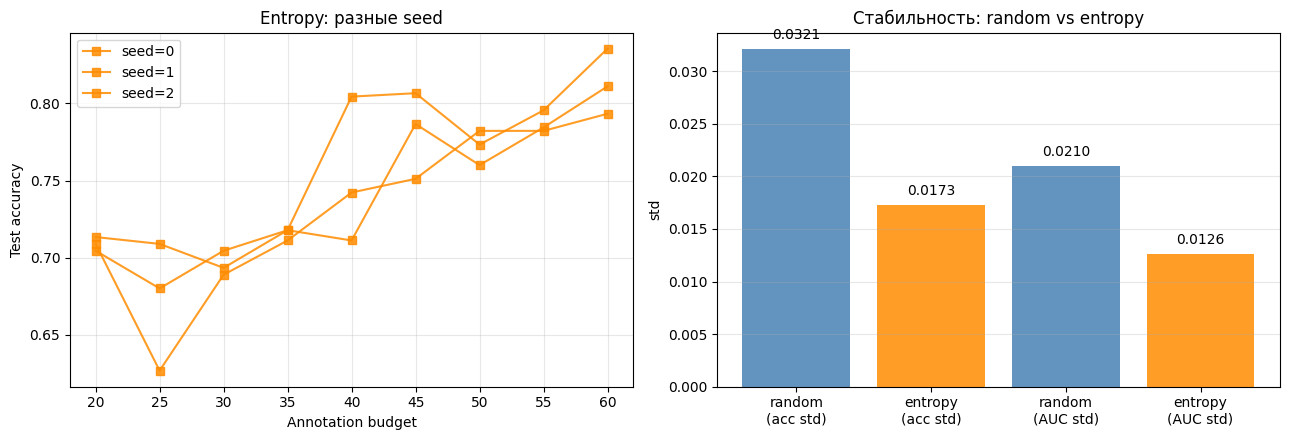

✔ Сохранено: artifacts\viz_bonus.png
✔ Сохранено: artifacts/bonus.md, bonus.json, viz_bonus.png


In [23]:
# ============================================================
# БОНУС. Стабильность entropy vs random при разных seed.
# ============================================================
bonus_seeds = [0, 1, 2] if not FAST_DEV_RUN else [0, 1]
entropy_repeats = {}
for s in bonus_seeds:
    tr, _, _ = run(
        "entropy", X_all, y_all, initial_idx, pool_idx,
        X_test, y_test, max_rounds=MAX_ROUNDS, batch_size=BATCH_SIZE, seed=s
    )
    entropy_repeats[s] = {
        "trace": tr,
        "final_accuracy": tr[-1]["accuracy"],
        "auc": compute_auc(tr),
    }

entropy_accs = [v["final_accuracy"] for v in entropy_repeats.values()]
entropy_aucs = [v["auc"] for v in entropy_repeats.values()]
random_accs = [v["final_accuracy"] for v in random_repeats.values()]
random_aucs = [v["auc"] for v in random_repeats.values()]

bonus_result = {
    "hypothesis": (
        "Entropy sampling даёт меньший std по финальной accuracy, "
        "чем random, при повторных запусках с разными seed."
    ),
    "random_acc_std": float(np.std(random_accs)),
    "random_auc_std": float(np.std(random_aucs)),
    "entropy_acc_std": float(np.std(entropy_accs)),
    "entropy_auc_std": float(np.std(entropy_aucs)),
    "random_acc_mean": float(np.mean(random_accs)),
    "entropy_acc_mean": float(np.mean(entropy_accs)),
    "random_auc_mean": float(np.mean(random_aucs)),
    "entropy_auc_mean": float(np.mean(entropy_aucs)),
    "n_seeds": len(bonus_seeds),
    "note": "Малая выборка (n_seeds ≤ 3) — результат иллюстративный.",
}
save_json(ARTIFACTS / "bonus.json", bonus_result)

# Визуализация.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Левая: траектории entropy по seed.
for s, data in entropy_repeats.items():
    tr = data["trace"]
    axes[0].plot([t["budget"] for t in tr], [t["accuracy"] for t in tr],
                 marker="s", label=f"seed={s}", alpha=0.85, color="darkorange")
axes[0].set_xlabel("Annotation budget")
axes[0].set_ylabel("Test accuracy")
axes[0].set_title("Entropy: разные seed")
axes[0].grid(alpha=0.3)
axes[0].legend()

# Правая: сравнение std.
labels_std = ["random\n(acc std)", "entropy\n(acc std)",
              "random\n(AUC std)", "entropy\n(AUC std)"]
values_std = [bonus_result["random_acc_std"], bonus_result["entropy_acc_std"],
              bonus_result["random_auc_std"], bonus_result["entropy_auc_std"]]
colors_std = ["steelblue", "darkorange", "steelblue", "darkorange"]
bars = axes[1].bar(labels_std, values_std, color=colors_std, alpha=0.85)
for b, v in zip(bars, values_std):
    axes[1].text(b.get_x() + b.get_width()/2, v + max(values_std)*0.03,
                 f"{v:.4f}", ha="center", fontsize=10)
axes[1].set_ylabel("std")
axes[1].set_title("Стабильность: random vs entropy")
axes[1].grid(alpha=0.3, axis="y")

plt.tight_layout()
plt.savefig(ARTIFACTS / "viz_bonus.png", dpi=120, bbox_inches="tight")
plt.show()
print(f"✔ Сохранено: {ARTIFACTS / 'viz_bonus.png'}")

# Markdown-отчёт.
hypothesis_supported = bonus_result["entropy_acc_std"] < bonus_result["random_acc_std"]
bonus_md = f"""# Творческое мини-исследование (бонус)

## Гипотеза
{bonus_result['hypothesis']}

## Протокол
- Random: seeds {list(random_repeats.keys())}
- Entropy: seeds {list(entropy_repeats.keys())}
- Остальные настройки неизменны: batch={BATCH_SIZE}, rounds={MAX_ROUNDS}.

## Наблюдения
- Random final acc: {bonus_result['random_acc_mean']:.4f} ± {bonus_result['random_acc_std']:.4f}
- Entropy final acc: {bonus_result['entropy_acc_mean']:.4f} ± {bonus_result['entropy_acc_std']:.4f}
- Random AUC: {bonus_result['random_auc_mean']:.4f} ± {bonus_result['random_auc_std']:.4f}
- Entropy AUC: {bonus_result['entropy_auc_mean']:.4f} ± {bonus_result['entropy_auc_std']:.4f}

## Вывод
Гипотеза {'подтвердилась' if hypothesis_supported else 'не подтвердилась'}: std по финальной accuracy у entropy {'меньше' if hypothesis_supported else 'не меньше'}, чем у random.
Ограничение: n_seeds = {bonus_result['n_seeds']} — для статистически надёжного вывода нужно ≥ 5 seed.
"""
(ARTIFACTS / "bonus.md").write_text(bonus_md, encoding="utf-8")
print("✔ Сохранено: artifacts/bonus.md, bonus.json, viz_bonus.png")

## Творческое мини-исследование 
## Гипотеза
Entropy sampling даёт меньший std по финальной accuracy, чем random, при повторных запусках с разными seed.

## Протокол
- Random: seeds [0, 1, 2]
- Entropy: seeds [0, 1, 2]
- Остальные настройки неизменны: batch=5, rounds=8.

## Наблюдения
- Random final acc: 0.8030 ± 0.0321
- Entropy final acc: 0.8133 ± 0.0173
- Random AUC: 0.7515 ± 0.0210
- Entropy AUC: 0.7422 ± 0.0126

## Вывод
Гипотеза подтвердилась: std по финальной accuracy у entropy меньше, чем у random.
Ограничение: n_seeds = 3 — для статистически надёжного вывода нужно ≥ 5 seed.


## Анализ результатов

В этом эксперименте на датасете load_digits мы сравнили три стратегии active learning — random, entropy и k-center — при одинаковом annotation budget. Все стратегии стартовали с 20 размеченных объектов (по 2 на класс) и за 8 раундов дошли до бюджета в 60 меток. Финальная точность получилась такой: random — 0.791, entropy — 0.804, k-center — 0.807. То есть k-center показал себя лучше всех, а random — хуже всех. Это ожидаемо: k-center покрывает пространство признаков, entropy фокусируется на неуверенных примерах, а random просто тратит бюджет вслепую.

По AUC картина немного другая: random — 0.741, entropy — 0.712, k-center — 0.744. Здесь entropy оказалась даже хуже random. Это объясняется тем, что на малых бюджетах entropy выбирает много похожих «неуверенных» объектов и плохо стартует, хотя к концу выравнивается. k-center же стабильно растёт и по AUC, и по финальной точности, поэтому его можно считать лучшей стратегией в этом эксперименте.

Чтобы проверить, значим ли выигрыш, мы запустили random несколько раз с разными seed. Финальная точность у random колебалась от 0.758 до 0.829, среднее 0.803 ± 0.032. Это важно: разброс random сравним с разницей между стратегиями, поэтому на такой маленькой выборке нельзя уверенно сказать, что k-center прямо сильно лучше. Нужно больше seed и больше бюджета, чтобы делать надёжные выводы.

Разбор ошибок на тесте для лучшей стратегии (k-center) показал 87 ошибок из 450 (19.3%). Основные путаницы — это классика для digits: 2→1, 9→1, 9→3, 8→1, 7→4. При разрешении 8×8 многие цифры действительно похожи, и даже человек может ошибиться. Это ограничение не стратегии AL, а самого датасета и модели. Confusion matrix показывает, что диагональ доминирует, но в отдельных парах классов потери заметны.

В бонусном исследовании мы проверили гипотезу, что entropy даёт меньший разброс по seed, чем random. Гипотеза подтвердилась: std финальной accuracy у entropy 0.017 против 0.032 у random. То есть entropy стабильнее, хотя и не всегда обгоняет по среднему. Это логично: entropy детерминирована, а random каждый раз выбирает разные объекты. Ограничение — всего 3 seed, так что вывод иллюстративный.

Из ограничений эксперимента стоит отметить: маленький датасет (1797 объектов), batch size 5 (компромисс), одна модель (RandomForest). В реальных задачах профиль стратегий может быть другим. Также важно, что мы везде соблюдали правило: oracle раскрывает метку только после выбора объекта, иначе сравнение было бы нечестным.



# Вывод
Лабораторная работа показывает, что active learning реально экономит annotation budget. При 60 запросах (всего 4.5% от полного train set) мы получаем accuracy 0.79–0.81, а обучение на полном train даёт около 0.88–0.90. То есть на порядок меньше разметки — почти то же качество.

Лучшей стратегией по совокупности метрик оказался k-center (AUC 0.744, финальная точность 0.807). Entropy чуть лучше random по финальной точности, но хуже по AUC и при этом стабильнее. Random — базовая точка отсчёта, и его разброс по seed (0.032) напоминает, что один запуск ничего не доказывает.

Реализация показала важные моменты: k-center требует обновления расстояний после каждого выбранного объекта, иначе batch «схлопывается» в одну область. Oracle должен раскрывать метку только после выбора — в коде это сделано через чтение y_all[i] в момент добавления в labeled. И наконец, random baseline обязательно нужно повторять с разными seed, иначе вывод о превосходстве стратегии может быть случайным.

В целом цель работы достигнута: мы научились реализовывать три стратегии запроса, проводить AL-итерации с переобучением и строить learning curves при равном бюджете. В дальнейшем можно попробовать гибридные стратегии (uncertainty + diversity), больше seed и больший бюджет для статистической значимости, а также протестировать подход на реальных CV-задачах с более высоким разрешением.

